In [1]:

%cd ..

from pathlib import Path
print(Path.cwd())

import numpy as np
import matplotlib.pyplot as plt

from hardware import ammeter, ammeter_uncertainty, gaussmeter, gaussmeter_uncertainty, horizontal_coils, vertical_coils, modulation_coils, horizontal_coils_uncertainty, vertical_coils_uncertainty, modulation_coils_uncertainty
from scope_header import DSOX1204G, self_test, load_waveforms


plt.rcParams.update({
    "font.sans-serif": ["Cabin", "Libertinus Sans", "DejaVu Sans"],
    "font.serif": ["Libertinus Serif"],
    "font.family": "sans-serif",
    "font.style": "normal",
    "font.weight": "normal",
    "font.size": 14,
    "axes.labelsize": 16,
    "axes.titlesize": 18,
    "axes.titleweight": "bold",
    "axes.labelweight": "normal",
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 14,
    "legend.title_fontsize": 14,
    "figure.titlesize": 18,
    "figure.titleweight": "bold",
    "mathtext.fontset": "cm",
    "mathtext.default": "it",
    "axes.unicode_minus": False,
    "text.color": "black",
    "axes.labelcolor": "black",
    "axes.titlecolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",
    "legend.edgecolor": "black",
})
%matplotlib inline

from scipy.optimize import curve_fit
from scipy import signal

# scope = DSOX1204G()


c:\Users\njwan\OneDrive - University of Toronto\Documents\Year 3\3F\PHY327\1 - Optical Pumping in Rubidium\code
c:\Users\njwan\OneDrive - University of Toronto\Documents\Year 3\3F\PHY327\1 - Optical Pumping in Rubidium\code


0.00929110150776293 1.084392404342672 -1.0676526425152382 1.6183019522335176 -1.5876763268987748
-2.1276714623540392e-09 0.25107753317213866 0.4543508420802871
0.14484925715687744 0.03656878557133178 0.03393529153057638
-2.939950452599812 0.012905580420160186


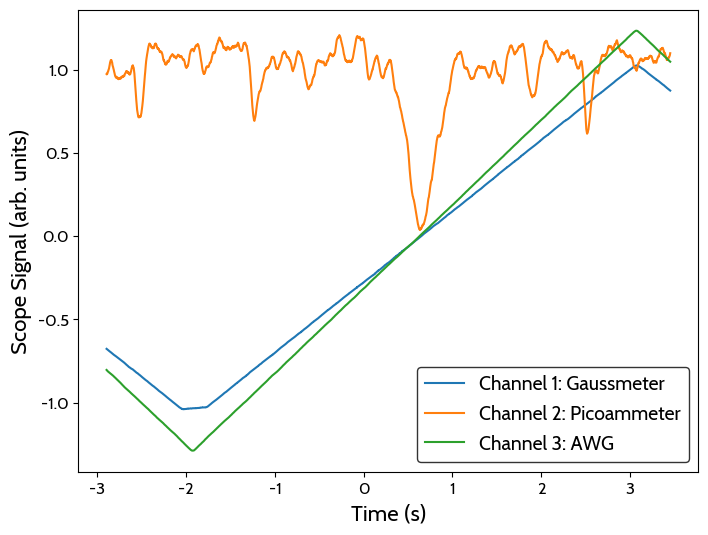

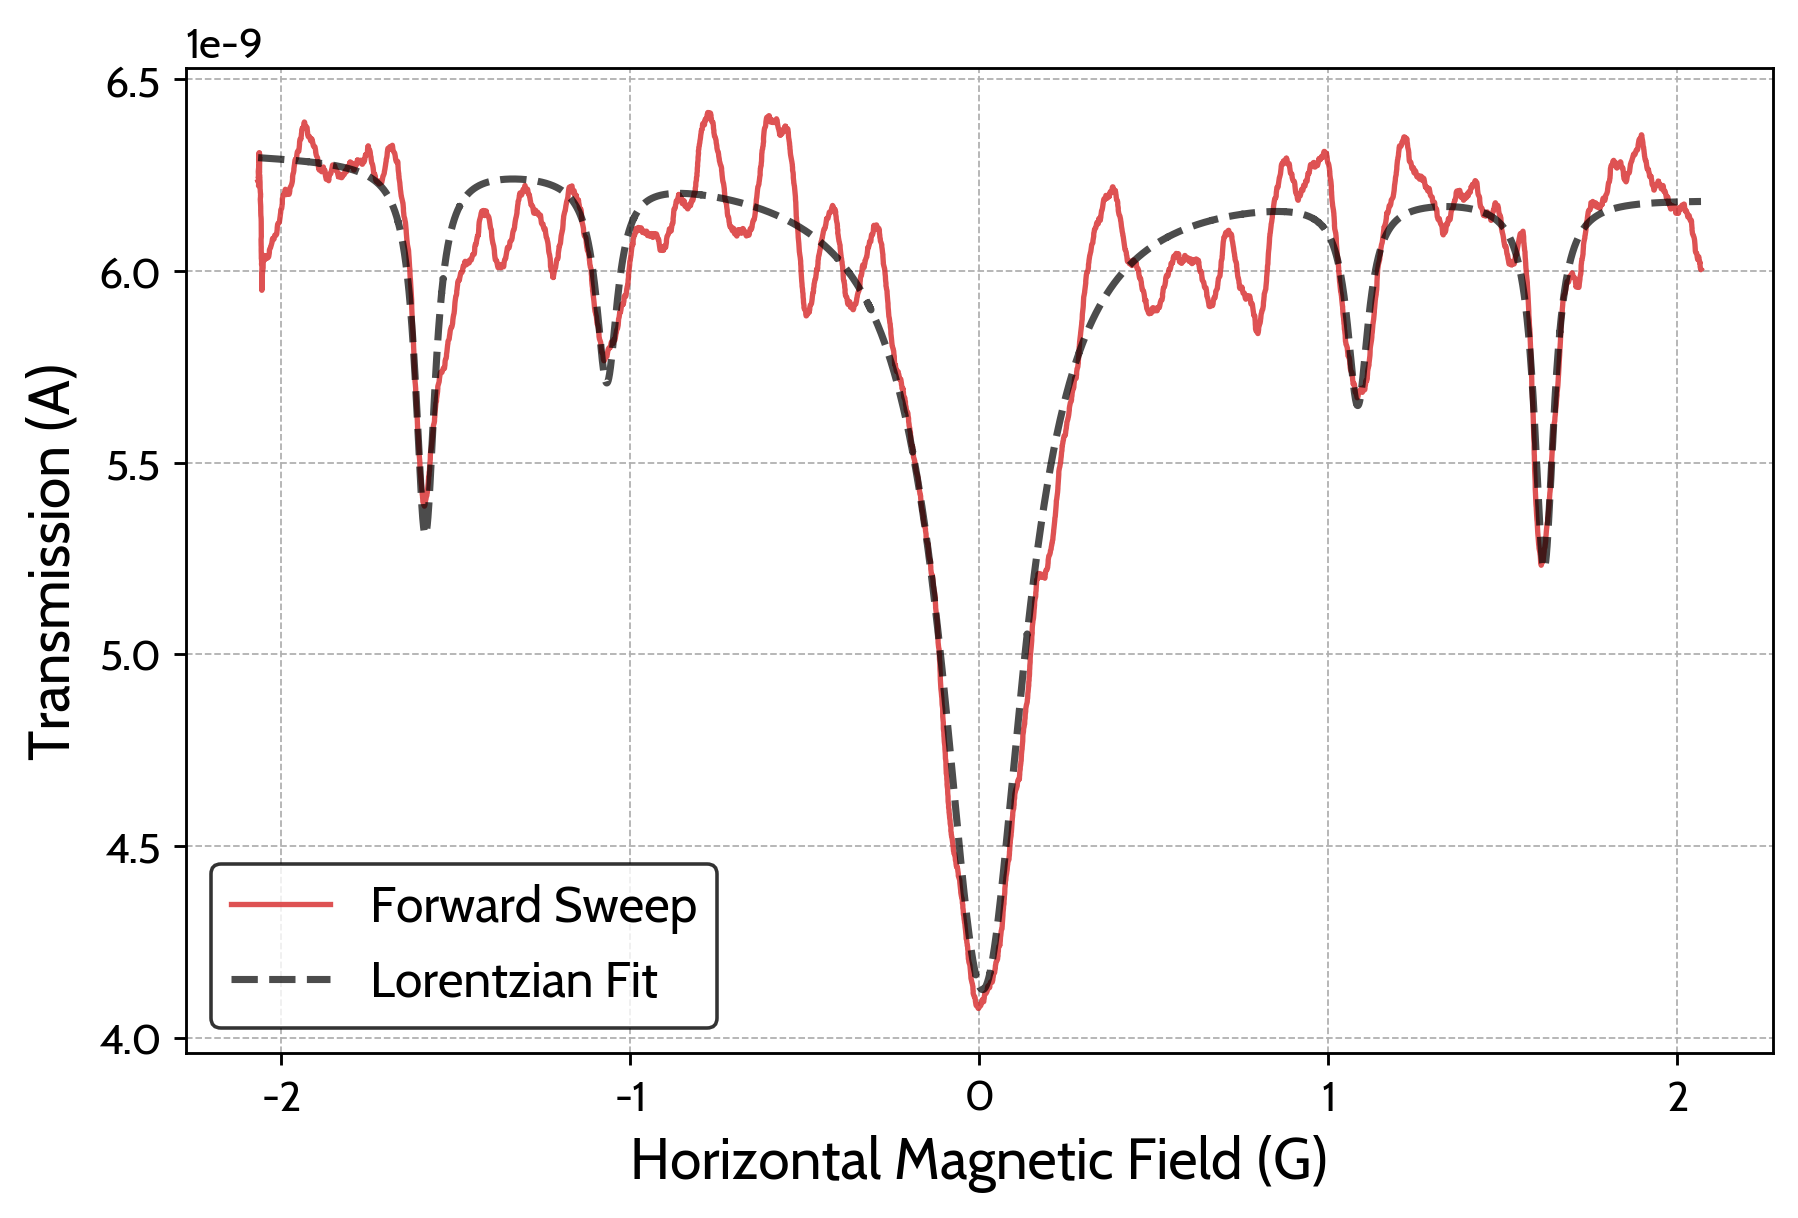

In [99]:
# 650 kHz
t, V1, V2, V3 = np.loadtxt("data/22/scope_13.csv", delimiter=",", unpack=True, skiprows = 2)


N = 400
t = np.convolve(t, np.ones(N)/N, mode='valid')
V1 = np.convolve(V1, np.ones(N)/N, mode='valid')
V2 = np.convolve(V2, np.ones(N)/N, mode='valid')
V3 = np.convolve(V3, np.ones(N)/N, mode='valid')

fig0, ax0 = plt.subplots(figsize=(8, 6))
ax0.plot(t, V1, label='Channel 1: Gaussmeter', color='tab:blue')
ax0.plot(t, V2*5-2, label='Channel 2: Picoammeter', color='tab:orange')
ax0.plot(t, V3, label='Channel 3: AWG', color='tab:green')
ax0.set_xlabel('Time (s)')
ax0.set_ylabel('Scope Signal (arb. units)')
ax0.legend()

# forward
mask = (t > -1.92) & (t < 3.07)
transmission_forward = ammeter(V2[mask]*1e3)
field_forward = gaussmeter(V1[mask]*1e3)

# fit to 5 lorenzians

def f(x, a, b, c, a1, b1, b1_neg, c1, a2, b2, b2_neg, c2, d, e):
    return a*(1/(1 + ((x-b)/c)**2) + 
            a1/(1 + ((x-b1)/c1)**2) + 
            a1/(1 + ((x-b1_neg)/c1)**2) +
            a2/(1 + ((x-b2)/c2)**2) + 
            a2/(1 + ((x-b2_neg)/c2)**2) + d + e*x)


guess1 = 1.07
guess2 = 1.61

popt, pcov = curve_fit(f, field_forward[field_forward > -1], transmission_forward[field_forward > -1], 
                       p0 = [
                           -2.2e-9, 0, .1, 
                            0.26, guess1, -guess1-0.015, 0.04, 
                            0.45, guess2, -guess2 + 0.02, 0.04,
                            -3, 0],
                        bounds = ([-np.inf, -np.inf, 0, 
                                   0, guess1 - 0.1, -guess1 - 0.1, 0.02, 
                                   0, guess2 - 0.1, -guess2 - 0.1, 0.02, 
                                   -np.inf, -np.inf],
                                  [np.inf, np.inf, np.inf, 
                                   np.inf, guess1 + 0.1, -guess1 + 0.1, np.inf, 
                                   np.inf, guess2 + 0.1, -guess2 + 0.1, np.inf, 
                                   np.inf, np.inf]))
a, b, c, a1, b1, b1_neg, c1, a2, b2, b2_neg, c2, d, e = popt
sigma_a, sigma_b, sigma_c, sigma_a1, sigma_b1, sigma_b1_neg, sigma_c1, sigma_a2, sigma_b2, sigma_b2_neg, sigma_c2, sigma_d, sigma_e = np.sqrt(np.diag(pcov))

fig, ax = plt.subplots(figsize=(8, 5), dpi = 256)

ax.plot(field_forward, transmission_forward, label='Forward Sweep', color='tab:red', alpha = 0.8)
ax.plot(field_forward, f(field_forward, *popt), label='Lorentzian Fit', lw = 2, ls = '--', color='k', alpha = 0.7)

ax.set_xlabel('Horizontal Magnetic Field (G)')
ax.set_ylabel('Transmission (A)')
ax.grid(True, which='both', linestyle='--', linewidth=0.5)
ax.legend()

print(b, b1, b1_neg, b2, b2_neg)
print(a, a1, a2)
print(c, c1, c2)
print(d, e)

In [3]:
print(f"b = {b:.4f} ± {sigma_b:.4f}")
print(f"b1 = {b1:.4f} ± {sigma_b1:.4f}")
print(f"b1_neg = {b1_neg:.4f} ± {sigma_b1_neg:.4f}")
print(f"b2 = {b2:.4f} ± {sigma_b2:.4f}")
print(f"b2_neg = {b2_neg:.5f} ± {sigma_b2_neg:.5f}")

peak1 = b1 - b1_neg
peak1_uncertainty = np.sqrt(sigma_b1**2 + sigma_b1_neg**2)

peak2 = b2 - b2_neg
peak2_uncertainty = np.sqrt(sigma_b2**2 + sigma_b2_neg**2)

print()
print(f"Peak 1 = {peak1:.4f} ± {peak1_uncertainty:.4f}")
print(f"Peak 2 = {peak2:.4f} ± {peak2_uncertainty:.4f}")

b = 0.0093 ± 0.0002
b1 = 1.0844 ± 0.0005
b1_neg = -1.0677 ± 0.0037
b2 = 1.6183 ± 0.0003
b2_neg = -1.58768 ± 0.00002

Peak 1 = 2.1520 ± 0.0037
Peak 2 = 3.2060 ± 0.0003



Peak 1 = 1.9278 ± 0.0144
Peak 2 = 2.9565 ± 0.0013


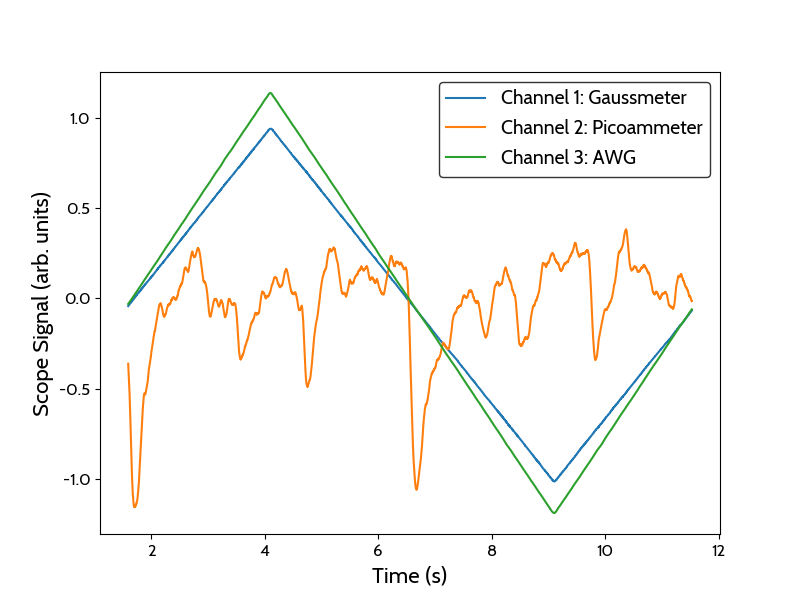

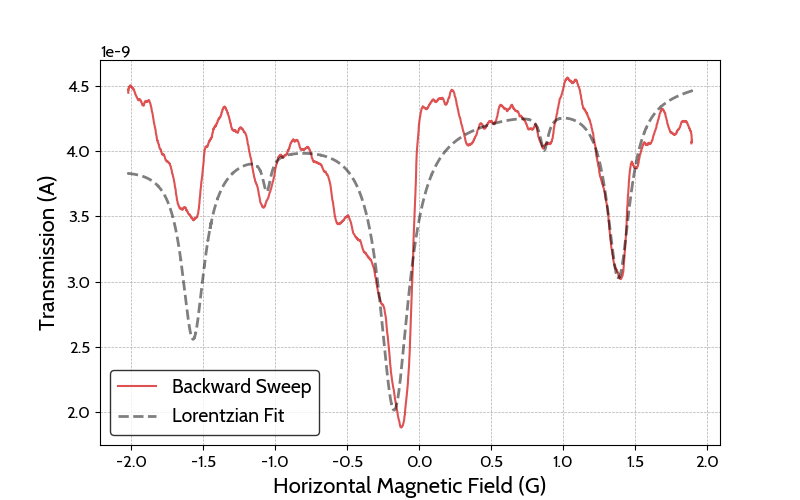

In [71]:
# 600 kHz
t, V1, V2, V3 = np.loadtxt("data/22/scope_14.csv", delimiter=",", unpack=True, skiprows = 2)


N = 400
t = np.convolve(t, np.ones(N)/N, mode='valid')
V1 = np.convolve(V1, np.ones(N)/N, mode='valid')
V2 = np.convolve(V2, np.ones(N)/N, mode='valid')
V3 = np.convolve(V3, np.ones(N)/N, mode='valid')

fig0, ax0 = plt.subplots(figsize=(8, 6))
ax0.plot(t, V1, label='Channel 1: Gaussmeter', color='tab:blue')
ax0.plot(t, V2*5-2, label='Channel 2: Picoammeter', color='tab:orange')
ax0.plot(t, V3, label='Channel 3: AWG', color='tab:green')
ax0.set_xlabel('Time (s)')
ax0.set_ylabel('Scope Signal (arb. units)')
ax0.legend()

# forward
mask = (t > 4.09) & (t < 9.11)
transmission_forward = ammeter(V2[mask]*1e3)
field_forward = gaussmeter(V1[mask]*1e3)

# fit to 5 lorenzians

def f(x, a, b, c, a1, b1, b1_neg, c1, a2, b2, b2_neg, c2, d, e):
    return a*(1/(1 + ((x-b)/c)**2) + 
            a1/(1 + ((x-b1)/c1)**2) + 
            a1/(1 + ((x-b1_neg)/c1)**2) +
            a2/(1 + ((x-b2)/c2)**2) + 
            a2/(1 + ((x-b2_neg)/c2)**2) + d + e*x)


guess1 = 1.08
guess2 = 1.62

popt, pcov = curve_fit(f, field_forward[field_forward > -1], transmission_forward[field_forward > -1], 
                       p0 = [
                           -2.2e-9, 0, .1, 
                            0.26, 0.9, -1.105, 0.04, 
                            0.45, 1.3, -1.67, 0.04,
                            -3, 0],
                        bounds = ([-np.inf, -np.inf, 0, 
                                   0, 0.9 - 0.1, -1.105 - 0.2, 0.02, 
                                   0, 1.3 - 0.1, -1.67 - 0.2, 0.02, 
                                   -np.inf, -np.inf],
                                  [np.inf, np.inf, np.inf, 
                                   np.inf, 0.9 + 0.1, -1.105 + 0.1, np.inf, 
                                   np.inf, 1.3 + 0.1, -1.67 + 0.1, np.inf, 
                                   np.inf, np.inf]))
a, b, c, a1, b1, b1_neg, c1, a2, b2, b2_neg, c2, d, e = popt
sigma_a, sigma_b, sigma_c, sigma_a1, sigma_b1, sigma_b1_neg, sigma_c1, sigma_a2, sigma_b2, sigma_b2_neg, sigma_c2, sigma_d, sigma_e = np.sqrt(np.diag(pcov))

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(field_forward, transmission_forward, label='Backward Sweep', color='tab:red', alpha = 0.8)
ax.plot(field_forward, f(field_forward, *popt), label='Lorentzian Fit', lw = 2, ls = '--', color='k', alpha = 0.5)

ax.set_xlabel('Horizontal Magnetic Field (G)')
ax.set_ylabel('Transmission (A)')
ax.grid(True, which='both', linestyle='--', linewidth=0.5)
ax.legend()

peak1 = b1 - b1_neg
peak1_uncertainty = np.sqrt(sigma_b1**2 + sigma_b1_neg**2)

peak2 = b2 - b2_neg
peak2_uncertainty = np.sqrt(sigma_b2**2 + sigma_b2_neg**2)

print()
print(f"Peak 1 = {peak1:.4f} ± {peak1_uncertainty:.4f}")
print(f"Peak 2 = {peak2:.4f} ± {peak2_uncertainty:.4f}")


Peak 1 = 1.7768 ± 0.0037
Peak 2 = 2.6950 ± 0.0778


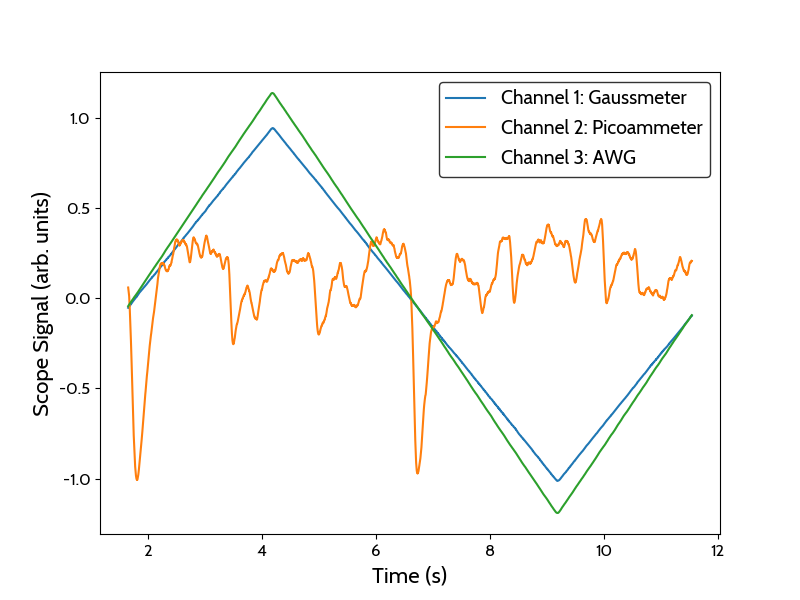

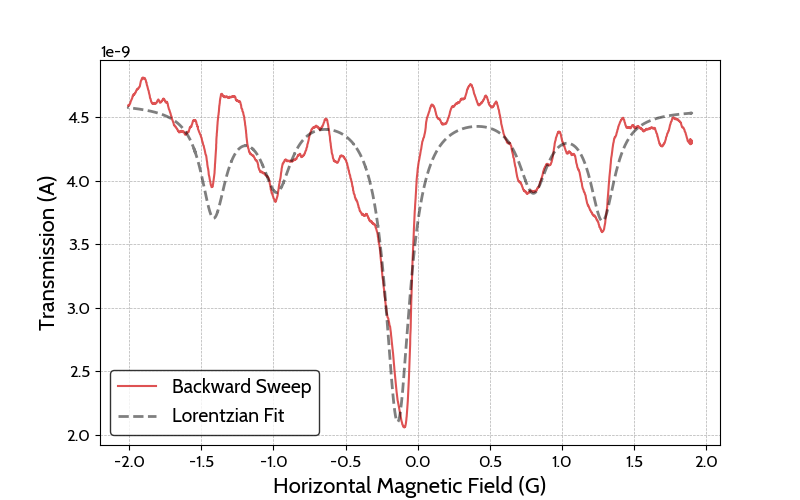

In [72]:
# 550 kHz
t, V1, V2, V3 = np.loadtxt("data/22/scope_15.csv", delimiter=",", unpack=True, skiprows = 2)


N = 400
t = np.convolve(t, np.ones(N)/N, mode='valid')
V1 = np.convolve(V1, np.ones(N)/N, mode='valid')
V2 = np.convolve(V2, np.ones(N)/N, mode='valid')
V3 = np.convolve(V3, np.ones(N)/N, mode='valid')

fig0, ax0 = plt.subplots(figsize=(8, 6))
ax0.plot(t, V1, label='Channel 1: Gaussmeter', color='tab:blue')
ax0.plot(t, V2*5-2, label='Channel 2: Picoammeter', color='tab:orange')
ax0.plot(t, V3, label='Channel 3: AWG', color='tab:green')
ax0.set_xlabel('Time (s)')
ax0.set_ylabel('Scope Signal (arb. units)')
ax0.legend()

# forward
mask = (t > 4.16) & (t < 9.16)
transmission_forward = ammeter(V2[mask]*1e3)
field_forward = gaussmeter(V1[mask]*1e3)

# fit to 5 lorenzians

def f(x, a, b, c, a1, b1, b1_neg, c1, a2, b2, b2_neg, c2, d, e):
    return a*(1/(1 + ((x-b)/c)**2) + 
            a1/(1 + ((x-b1)/c1)**2) + 
            a1/(1 + ((x-b1_neg)/c1)**2) +
            a2/(1 + ((x-b2)/c2)**2) + 
            a2/(1 + ((x-b2_neg)/c2)**2) + d + e*x)


guess1 = 0.9
guess2 = 1.38

popt, pcov = curve_fit(f, field_forward[field_forward > -1], transmission_forward[field_forward > -1], 
                       p0 = [
                           -5e-9, -0.1, .1, 
                            0.26, guess1, -guess1-0.08, 0.04, 
                            0.45, guess2, -1.425, 0.02,
                            -3, 0],
                        bounds = ([-np.inf, -np.inf, 0, 
                                   0, guess1 - 0.1, -guess1 - 0.1, 0.02, 
                                   0, guess2 - 0.1, -1.425 - 0.01, 0.02, 
                                   -np.inf, -np.inf],
                                  [np.inf, np.inf, np.inf, 
                                   np.inf, guess1 + 0.1, -guess1 + 0.1, np.inf, 
                                   np.inf, guess2 + 0.1, -1.425 + 0.01, np.inf, 
                                   np.inf, np.inf]))
a, b, c, a1, b1, b1_neg, c1, a2, b2, b2_neg, c2, d, e = popt
sigma_a, sigma_b, sigma_c, sigma_a1, sigma_b1, sigma_b1_neg, sigma_c1, sigma_a2, sigma_b2, sigma_b2_neg, sigma_c2, sigma_d, sigma_e = np.sqrt(np.diag(pcov))

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(field_forward, transmission_forward, label='Backward Sweep', color='tab:red', alpha = 0.8)
ax.plot(field_forward, f(field_forward, *popt), label='Lorentzian Fit', lw = 2, ls = '--', color='k', alpha = 0.5)

ax.set_xlabel('Horizontal Magnetic Field (G)')
ax.set_ylabel('Transmission (A)')
ax.grid(True, which='both', linestyle='--', linewidth=0.5)
ax.legend()

peak1 = b1 - b1_neg
peak1_uncertainty = np.sqrt(sigma_b1**2 + sigma_b1_neg**2)

peak2 = b2 - b2_neg
peak2_uncertainty = np.sqrt(sigma_b2**2 + sigma_b2_neg**2)

print()
print(f"Peak 1 = {peak1:.4f} ± {peak1_uncertainty:.4f}")
print(f"Peak 2 = {peak2:.4f} ± {peak2_uncertainty:.4f}")


Peak 1 = 2.2322 ± 0.0145
Peak 2 = 3.2413 ± 0.0017


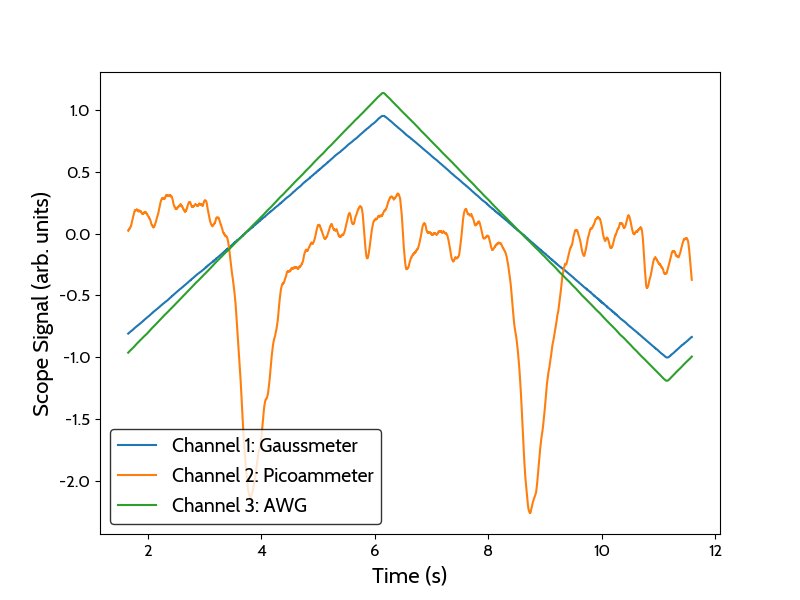

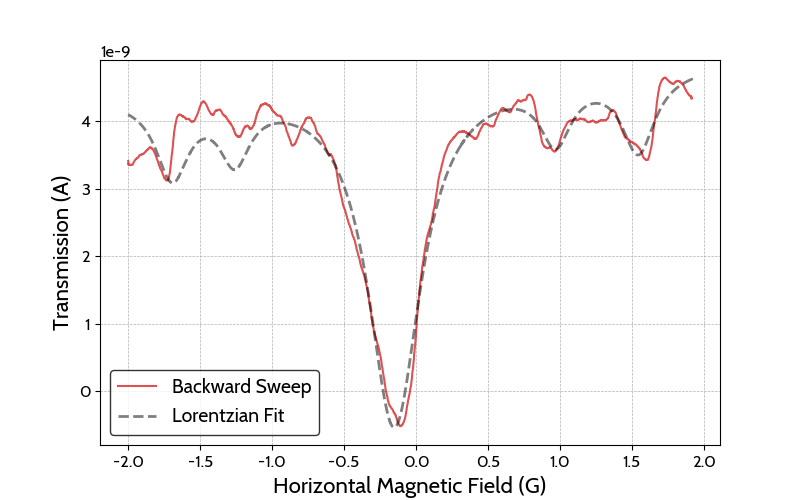

In [73]:
# 680 kHz
t, V1, V2, V3 = np.loadtxt("data/22/scope_16.csv", delimiter=",", unpack=True, skiprows = 2)


N = 400
t = np.convolve(t, np.ones(N)/N, mode='valid')
V1 = np.convolve(V1, np.ones(N)/N, mode='valid')
V2 = np.convolve(V2, np.ones(N)/N, mode='valid')
V3 = np.convolve(V3, np.ones(N)/N, mode='valid')

fig0, ax0 = plt.subplots(figsize=(8, 6))
ax0.plot(t, V1, label='Channel 1: Gaussmeter', color='tab:blue')
ax0.plot(t, V2*5-2, label='Channel 2: Picoammeter', color='tab:orange')
ax0.plot(t, V3, label='Channel 3: AWG', color='tab:green')
ax0.set_xlabel('Time (s)')
ax0.set_ylabel('Scope Signal (arb. units)')
ax0.legend()

# forward
mask = (t > 6.15) & (t < 11.16)
transmission_forward = ammeter(V2[mask]*1e3)
field_forward = gaussmeter(V1[mask]*1e3)

# fit to 5 lorenzians

def f(x, a, b, c, a1, b1, b1_neg, c1, a2, b2, b2_neg, c2, d, e):
    return a*(1/(1 + ((x-b)/c)**2) + 
            a1/(1 + ((x-b1)/c1)**2) + 
            a1/(1 + ((x-b1_neg)/c1)**2) +
            a2/(1 + ((x-b2)/c2)**2) + 
            a2/(1 + ((x-b2_neg)/c2)**2) + d + e*x)


guess1 = 0.9
guess2 = 1.6

popt, pcov = curve_fit(f, field_forward[field_forward > -1], transmission_forward[field_forward > -1], 
                       p0 = [
                           -5e-9, -0.1, .1, 
                            0.26, guess1, -1.2, 0.04, 
                            0.45, guess2, -1.7, 0.02,
                            -3, 0],
                        bounds = ([-np.inf, -np.inf, 0, 
                                   0, guess1 - 0.1, -1.2 - 0.1, 0.02, 
                                   0, guess2 - 0.1, -1.7 - 0.01, 0.02, 
                                   -np.inf, -np.inf],
                                  [np.inf, np.inf, np.inf, 
                                   np.inf, guess1 + 0.1, -1.2 + 0.1, np.inf, 
                                   np.inf, guess2 + 0.1, -1.7 + 0.01, np.inf, 
                                   np.inf, np.inf]))
a, b, c, a1, b1, b1_neg, c1, a2, b2, b2_neg, c2, d, e = popt
sigma_a, sigma_b, sigma_c, sigma_a1, sigma_b1, sigma_b1_neg, sigma_c1, sigma_a2, sigma_b2, sigma_b2_neg, sigma_c2, sigma_d, sigma_e = np.sqrt(np.diag(pcov))

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(field_forward, transmission_forward, label='Backward Sweep', color='tab:red', alpha = 0.8)
ax.plot(field_forward, f(field_forward, *popt), label='Lorentzian Fit', lw = 2, ls = '--', color='k', alpha = 0.5)

ax.set_xlabel('Horizontal Magnetic Field (G)')
ax.set_ylabel('Transmission (A)')
ax.grid(True, which='both', linestyle='--', linewidth=0.5)
ax.legend()

peak1 = b1 - b1_neg
peak1_uncertainty = np.sqrt(sigma_b1**2 + sigma_b1_neg**2)

peak2 = b2 - b2_neg
peak2_uncertainty = np.sqrt(sigma_b2**2 + sigma_b2_neg**2)

print()
print(f"Peak 1 = {peak1:.4f} ± {peak1_uncertainty:.4f}")
print(f"Peak 2 = {peak2:.4f} ± {peak2_uncertainty:.4f}")


Peak 1 = 2.0411 ± 0.0046
Peak 2 = 3.0794 ± 0.0009


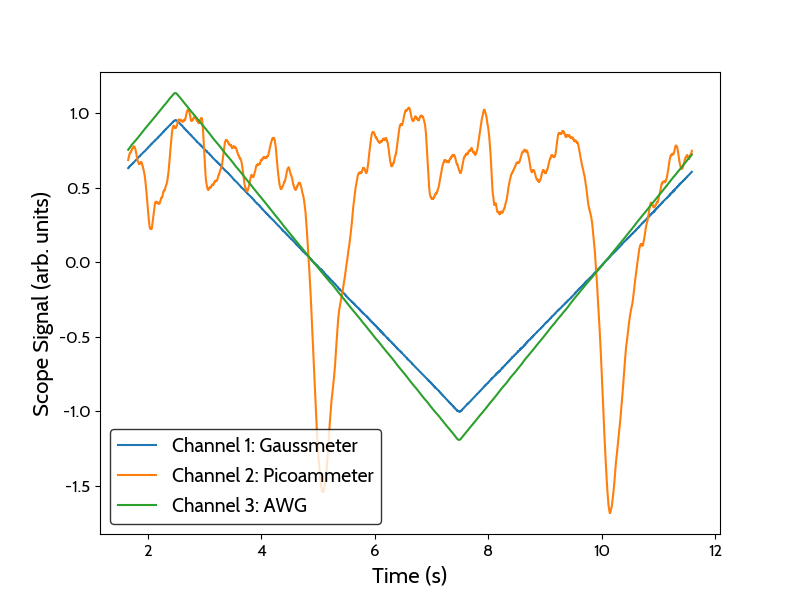

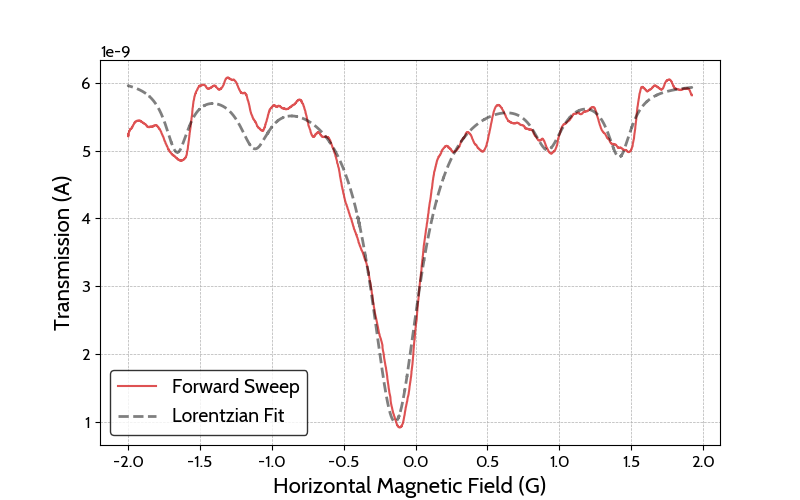

In [74]:
# 630 kHz
t, V1, V2, V3 = np.loadtxt("data/22/scope_17.csv", delimiter=",", unpack=True, skiprows = 2)


N = 400
t = np.convolve(t, np.ones(N)/N, mode='valid')
V1 = np.convolve(V1, np.ones(N)/N, mode='valid')
V2 = np.convolve(V2, np.ones(N)/N, mode='valid')
V3 = np.convolve(V3, np.ones(N)/N, mode='valid')

fig0, ax0 = plt.subplots(figsize=(8, 6))
ax0.plot(t, V1, label='Channel 1: Gaussmeter', color='tab:blue')
ax0.plot(t, V2*5-2, label='Channel 2: Picoammeter', color='tab:orange')
ax0.plot(t, V3, label='Channel 3: AWG', color='tab:green')
ax0.set_xlabel('Time (s)')
ax0.set_ylabel('Scope Signal (arb. units)')
ax0.legend()

# forward
mask = (t > 2.5) & (t < 7.5)
transmission_forward = ammeter(V2[mask]*1e3)
field_forward = gaussmeter(V1[mask]*1e3)

# fit to 5 lorenzians

def f(x, a, b, c, a1, b1, b1_neg, c1, a2, b2, b2_neg, c2, d, e):
    return a*(1/(1 + ((x-b)/c)**2) + 
            a1/(1 + ((x-b1)/c1)**2) + 
            a1/(1 + ((x-b1_neg)/c1)**2) +
            a2/(1 + ((x-b2)/c2)**2) + 
            a2/(1 + ((x-b2_neg)/c2)**2) + d + e*x)


guess1 = 0.95
guess2 = 1.4

popt, pcov = curve_fit(f, field_forward[field_forward > -1], transmission_forward[field_forward > -1], 
                       p0 = [
                           -5e-9, -0.115, .1, 
                            0.26, guess1, -1.07, 0.04, 
                            0.45, guess2, -1.66, 0.04,
                            -3, 0],
                        bounds = ([-np.inf, -np.inf, 0, 
                                   0, guess1 - 0.1, -1.07 - 0.05, 0.02, 
                                   0, guess2 - 0.1, -1.61 - 0.05, 0.02, 
                                   -np.inf, -np.inf],
                                  [np.inf, np.inf, np.inf, 
                                   np.inf, guess1 + 0.1, -1.07 + 0.05, np.inf, 
                                   np.inf, guess2 + 0.1, -1.61 + 0.05, np.inf, 
                                   np.inf, np.inf]))
a, b, c, a1, b1, b1_neg, c1, a2, b2, b2_neg, c2, d, e = popt
sigma_a, sigma_b, sigma_c, sigma_a1, sigma_b1, sigma_b1_neg, sigma_c1, sigma_a2, sigma_b2, sigma_b2_neg, sigma_c2, sigma_d, sigma_e = np.sqrt(np.diag(pcov))

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(field_forward, transmission_forward, label='Forward Sweep', color='tab:red', alpha = 0.8)
ax.plot(field_forward, f(field_forward, *popt), label='Lorentzian Fit', lw = 2, ls = '--', color='k', alpha = 0.5)

ax.set_xlabel('Horizontal Magnetic Field (G)')
ax.set_ylabel('Transmission (A)')
ax.grid(True, which='both', linestyle='--', linewidth=0.5)
ax.legend()

peak1 = b1 - b1_neg
peak1_uncertainty = np.sqrt(sigma_b1**2 + sigma_b1_neg**2)

peak2 = b2 - b2_neg
peak2_uncertainty = np.sqrt(sigma_b2**2 + sigma_b2_neg**2)

print()
print(f"Peak 1 = {peak1:.4f} ± {peak1_uncertainty:.4f}")
print(f"Peak 2 = {peak2:.4f} ± {peak2_uncertainty:.4f}")


Peak 1 = 1.9098 ± 0.0053
Peak 2 = 2.8722 ± 0.0009


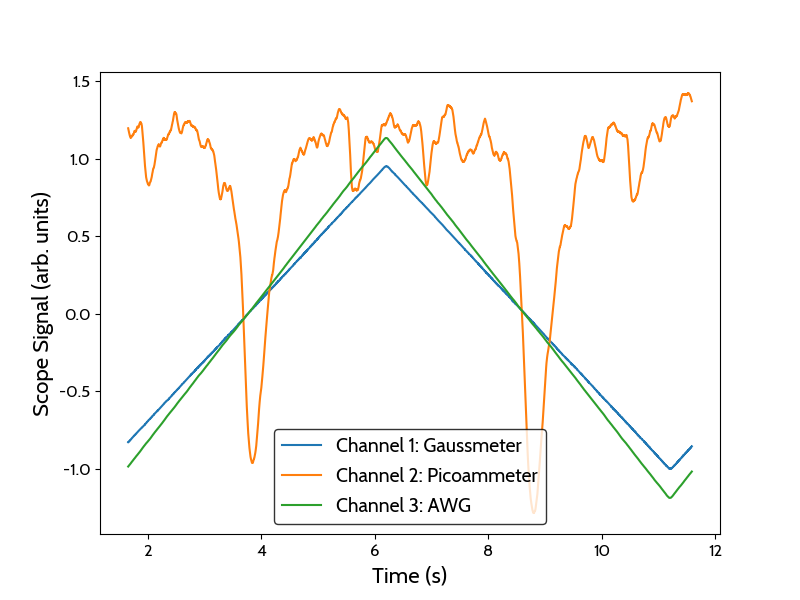

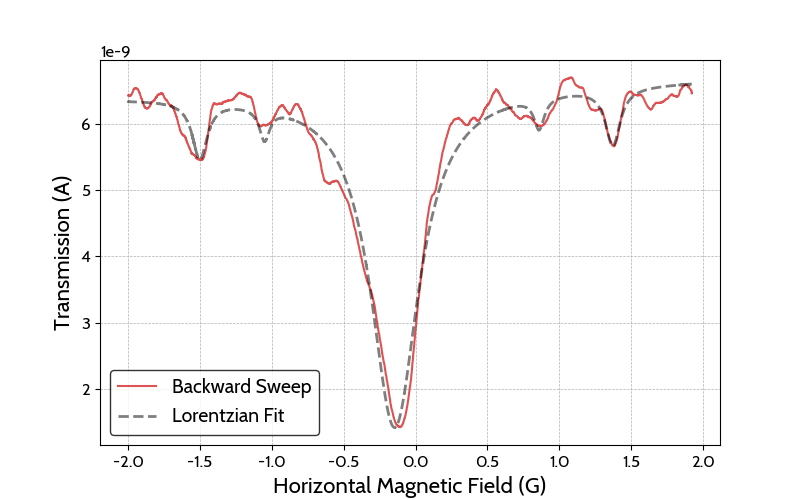

In [75]:
# 580 kHz
t, V1, V2, V3 = np.loadtxt("data/22/scope_18.csv", delimiter=",", unpack=True, skiprows = 2)


N = 400
t = np.convolve(t, np.ones(N)/N, mode='valid')
V1 = np.convolve(V1, np.ones(N)/N, mode='valid')
V2 = np.convolve(V2, np.ones(N)/N, mode='valid')
V3 = np.convolve(V3, np.ones(N)/N, mode='valid')

fig0, ax0 = plt.subplots(figsize=(8, 6))
ax0.plot(t, V1, label='Channel 1: Gaussmeter', color='tab:blue')
ax0.plot(t, V2*5-2, label='Channel 2: Picoammeter', color='tab:orange')
ax0.plot(t, V3, label='Channel 3: AWG', color='tab:green')
ax0.set_xlabel('Time (s)')
ax0.set_ylabel('Scope Signal (arb. units)')
ax0.legend()

# forward
mask = (t > 6.2) & (t < 11.2)
transmission_forward = ammeter(V2[mask]*1e3)
field_forward = gaussmeter(V1[mask]*1e3)

# fit to 5 lorenzians

def f(x, a, b, c, a1, b1, b1_neg, c1, a2, b2, b2_neg, c2, d, e):
    return a*(1/(1 + ((x-b)/c)**2) + 
            a1/(1 + ((x-b1)/c1)**2) + 
            a1/(1 + ((x-b1_neg)/c1)**2) +
            a2/(1 + ((x-b2)/c2)**2) + 
            a2/(1 + ((x-b2_neg)/c2)**2) + d + e*x)


guess1 = 0.817
guess2 = 1.373

popt, pcov = curve_fit(f, field_forward[field_forward > -1], transmission_forward[field_forward > -1], 
                       p0 = [
                           -5e-9, -0.122, .1, 
                            0.26, guess1, -1.0, 0.04, 
                            0.45, guess2, -1.5, 0.04,
                            -3, 0],
                        bounds = ([-np.inf, -np.inf, 0, 
                                   0, guess1 - 0.1, -0.95 - 0.1, 0.02, 
                                   0, guess2 - 0.1, -1.6 - 0.1, 0.02, 
                                   -np.inf, -np.inf],
                                  [np.inf, np.inf, np.inf, 
                                   np.inf, guess1 + 0.1, -0.95 + 0.1, np.inf, 
                                   np.inf, guess2 + 0.1, -1.6 + 0.1, np.inf, 
                                   np.inf, np.inf]))
a, b, c, a1, b1, b1_neg, c1, a2, b2, b2_neg, c2, d, e = popt
sigma_a, sigma_b, sigma_c, sigma_a1, sigma_b1, sigma_b1_neg, sigma_c1, sigma_a2, sigma_b2, sigma_b2_neg, sigma_c2, sigma_d, sigma_e = np.sqrt(np.diag(pcov))

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(field_forward, transmission_forward, label='Backward Sweep', color='tab:red', alpha = 0.8)
ax.plot(field_forward, f(field_forward, *popt), label='Lorentzian Fit', lw = 2, ls = '--', color='k', alpha = 0.5)

ax.set_xlabel('Horizontal Magnetic Field (G)')
ax.set_ylabel('Transmission (A)')
ax.grid(True, which='both', linestyle='--', linewidth=0.5)
ax.legend()

peak1 = b1 - b1_neg
peak1_uncertainty = np.sqrt(sigma_b1**2 + sigma_b1_neg**2)

peak2 = b2 - b2_neg
peak2_uncertainty = np.sqrt(sigma_b2**2 + sigma_b2_neg**2)

print()
print(f"Peak 1 = {peak1:.4f} ± {peak1_uncertainty:.4f}")
print(f"Peak 2 = {peak2:.4f} ± {peak2_uncertainty:.4f}")


Peak 1 = 2.0920 ± 0.0020
Peak 2 = 3.0292 ± 0.1169


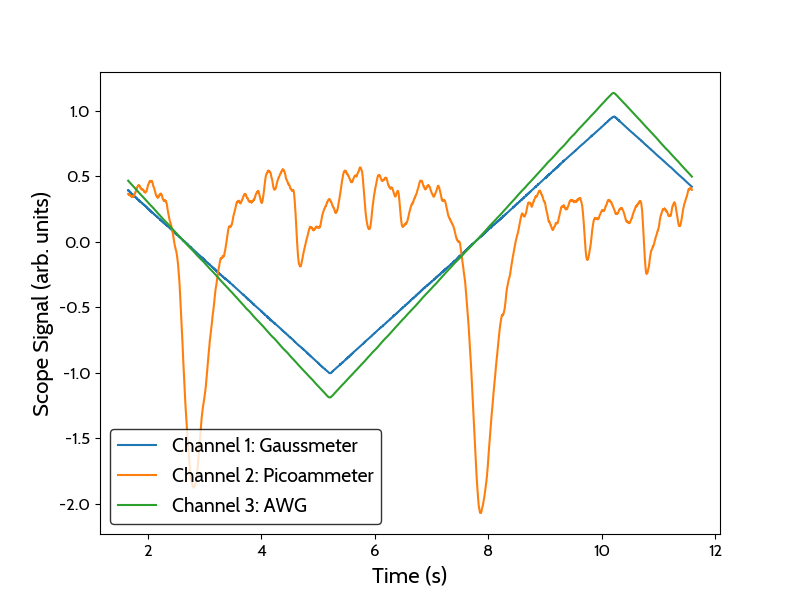

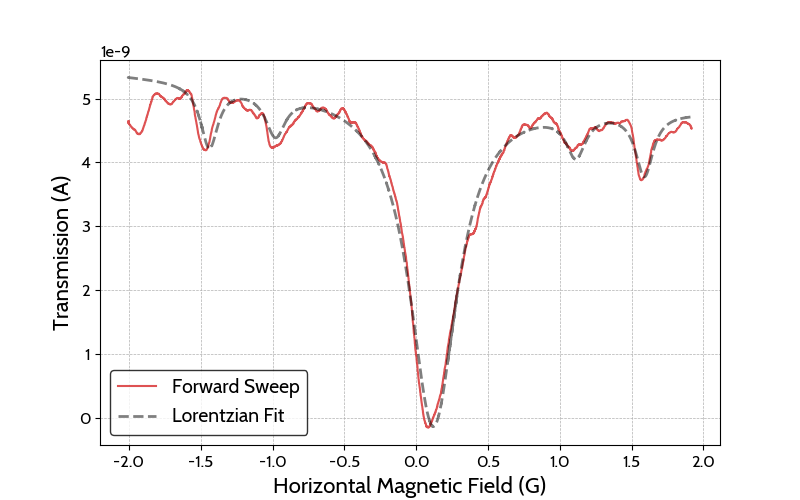

In [76]:
# 620 kHz
t, V1, V2, V3 = np.loadtxt("data/22/scope_19.csv", delimiter=",", unpack=True, skiprows = 2)


N = 400
t = np.convolve(t, np.ones(N)/N, mode='valid')
V1 = np.convolve(V1, np.ones(N)/N, mode='valid')
V2 = np.convolve(V2, np.ones(N)/N, mode='valid')
V3 = np.convolve(V3, np.ones(N)/N, mode='valid')

fig0, ax0 = plt.subplots(figsize=(8, 6))
ax0.plot(t, V1, label='Channel 1: Gaussmeter', color='tab:blue')
ax0.plot(t, V2*5-2, label='Channel 2: Picoammeter', color='tab:orange')
ax0.plot(t, V3, label='Channel 3: AWG', color='tab:green')
ax0.set_xlabel('Time (s)')
ax0.set_ylabel('Scope Signal (arb. units)')
ax0.legend()

# forward
mask = (t > 5.2) & (t < 10.2)
transmission_forward = ammeter(V2[mask]*1e3)
field_forward = gaussmeter(V1[mask]*1e3)

# fit to 5 lorenzians

def f(x, a, b, c, a1, b1, b1_neg, c1, a2, b2, b2_neg, c2, d, e):
    return a*(1/(1 + ((x-b)/c)**2) + 
            a1/(1 + ((x-b1)/c1)**2) + 
            a1/(1 + ((x-b1_neg)/c1)**2) +
            a2/(1 + ((x-b2)/c2)**2) + 
            a2/(1 + ((x-b2_neg)/c2)**2) + d + e*x)


guess1 = 1.08
guess2 = 1.54

popt, pcov = curve_fit(f, field_forward[field_forward > -1], transmission_forward[field_forward > -1], 
                       p0 = [
                           -5e-9, 0.076, .1, 
                            0.26, guess1, -guess1-0.08, 0.04, 
                            0.45, guess2, -guess2 - 0.06, 0.04,
                            -3, 0],
                        bounds = ([-np.inf, -np.inf, 0, 
                                   0, guess1 - 0.1, -guess1 - 0.1, 0.02, 
                                   0, guess2 - 0.1, -guess2 - 0.1, 0.02, 
                                   -np.inf, -np.inf],
                                  [np.inf, np.inf, np.inf, 
                                   np.inf, guess1 + 0.1, -guess1 + 0.1, np.inf, 
                                   np.inf, guess2 + 0.1, -guess2 + 0.1, np.inf, 
                                   np.inf, np.inf]))
a, b, c, a1, b1, b1_neg, c1, a2, b2, b2_neg, c2, d, e = popt
sigma_a, sigma_b, sigma_c, sigma_a1, sigma_b1, sigma_b1_neg, sigma_c1, sigma_a2, sigma_b2, sigma_b2_neg, sigma_c2, sigma_d, sigma_e = np.sqrt(np.diag(pcov))

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(field_forward, transmission_forward, label='Forward Sweep', color='tab:red', alpha = 0.8)
ax.plot(field_forward, f(field_forward, *popt), label='Lorentzian Fit', lw = 2, ls = '--', color='k', alpha = 0.5)

ax.set_xlabel('Horizontal Magnetic Field (G)')
ax.set_ylabel('Transmission (A)')
ax.grid(True, which='both', linestyle='--', linewidth=0.5)
ax.legend()

peak1 = b1 - b1_neg
peak1_uncertainty = np.sqrt(sigma_b1**2 + sigma_b1_neg**2)

peak2 = b2 - b2_neg
peak2_uncertainty = np.sqrt(sigma_b2**2 + sigma_b2_neg**2)

print()
print(f"Peak 1 = {peak1:.4f} ± {peak1_uncertainty:.4f}")
print(f"Peak 2 = {peak2:.4f} ± {peak2_uncertainty:.4f}")

-0.05448251150448155 0.9751825874759519 -1.0879999970390863 1.4882533989784428 -1.562795592508641
-3.5021678114067357e-09 0.1435618177278319 0.3520493664217925
0.12444926713658219 0.04713153078795641 0.04352829873598338
-2.759290374589936 0.1425735605015474


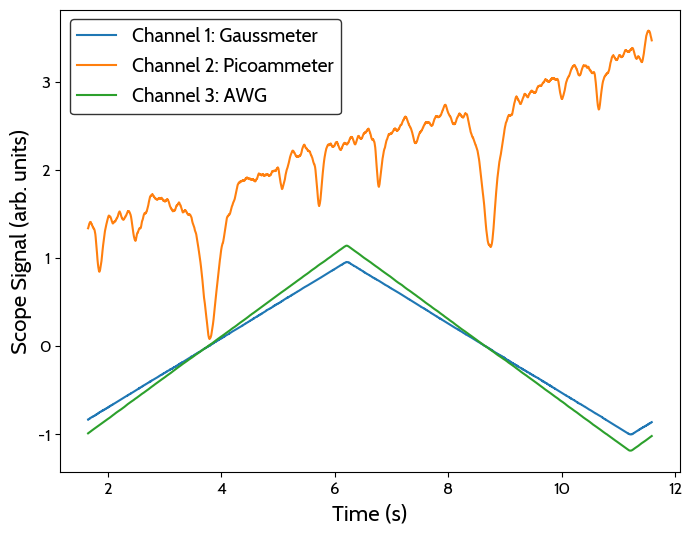

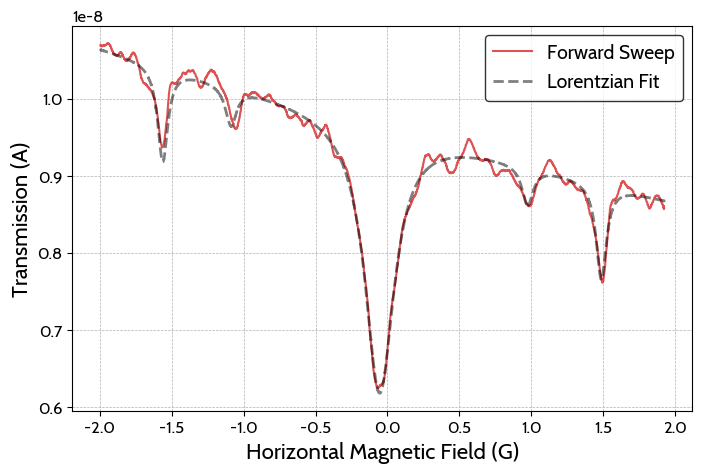

In [7]:
# 620 kHz with heat gun
t, V1, V2, V3 = np.loadtxt("data/22/scope_20.csv", delimiter=",", unpack=True, skiprows = 2)


N = 400
t = np.convolve(t, np.ones(N)/N, mode='valid')
V1 = np.convolve(V1, np.ones(N)/N, mode='valid')
V2 = np.convolve(V2, np.ones(N)/N, mode='valid')
V3 = np.convolve(V3, np.ones(N)/N, mode='valid')

fig0, ax0 = plt.subplots(figsize=(8, 6))
ax0.plot(t, V1, label='Channel 1: Gaussmeter', color='tab:blue')
ax0.plot(t, V2*5-2, label='Channel 2: Picoammeter', color='tab:orange')
ax0.plot(t, V3, label='Channel 3: AWG', color='tab:green')
ax0.set_xlabel('Time (s)')
ax0.set_ylabel('Scope Signal (arb. units)')
ax0.legend()

# forward
mask = (t > 6.2) & (t < 11.2)
transmission_forward = ammeter(V2[mask]*1e3)
field_forward = gaussmeter(V1[mask]*1e3)

# backward
mask = (t < 6.2)
transmission_backward = ammeter(V2[mask]*1e3)
field_backward = gaussmeter(V1[mask]*1e3)

# fit to 5 lorenzians

def f(x, a, b, c, a1, b1, b1_neg, c1, a2, b2, b2_neg, c2, d, e):
    return a*(1/(1 + ((x-b)/c)**2) + 
            a1/(1 + ((x-b1)/c1)**2) + 
            a1/(1 + ((x-b1_neg)/c1)**2) +
            a2/(1 + ((x-b2)/c2)**2) + 
            a2/(1 + ((x-b2_neg)/c2)**2) + d + e*x)


guess1 = .988
guess2 = 1.5

popt, pcov = curve_fit(f, field_forward[field_forward > -1], transmission_forward[field_forward > -1], 
                       p0 = [
                           -2.2e-9, 0, .1, 
                            0.26, guess1, -guess1-0.08, 0.04, 
                            0.45, guess2, -guess2 - 0.06, 0.04,
                            -3, 0],
                        bounds = ([-np.inf, -np.inf, 0, 
                                   0, guess1 - 0.1, -guess1 - 0.1, 0.02, 
                                   0, guess2 - 0.1, -guess2 - 0.1, 0.02, 
                                   -np.inf, -np.inf],
                                  [np.inf, np.inf, np.inf, 
                                   np.inf, guess1 + 0.1, -guess1 + 0.1, np.inf, 
                                   np.inf, guess2 + 0.1, -guess2 + 0.1, np.inf, 
                                   np.inf, np.inf]))
a, b, c, a1, b1, b1_neg, c1, a2, b2, b2_neg, c2, d, e = popt
sigma_a, sigma_b, sigma_c, sigma_a1, sigma_b1, sigma_b1_neg, sigma_c1, sigma_a2, sigma_b2, sigma_b2_neg, sigma_c2, sigma_d, sigma_e = np.sqrt(np.diag(pcov))

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(field_forward, transmission_forward, label='Forward Sweep', color='tab:red', alpha = 0.8)
#ax.plot(field_backward, transmission_backward, label='Backward Sweep', color='tab:blue', alpha = 0.8)
ax.plot(field_forward, f(field_forward, *popt), label='Lorentzian Fit', lw = 2, ls = '--', color='k', alpha = 0.5)

ax.set_xlabel('Horizontal Magnetic Field (G)')
ax.set_ylabel('Transmission (A)')
ax.grid(True, which='both', linestyle='--', linewidth=0.5)
ax.legend()

print(b, b1, b1_neg, b2, b2_neg)
print(a, a1, a2)
print(c, c1, c2)
print(d, e)

[ 0.00371458 -0.2411775 ] [0.00045016 0.27786944]
[0.00473113 0.12520166] [0.00031728 0.20306969]


(1.6834475737234023, 3.6)

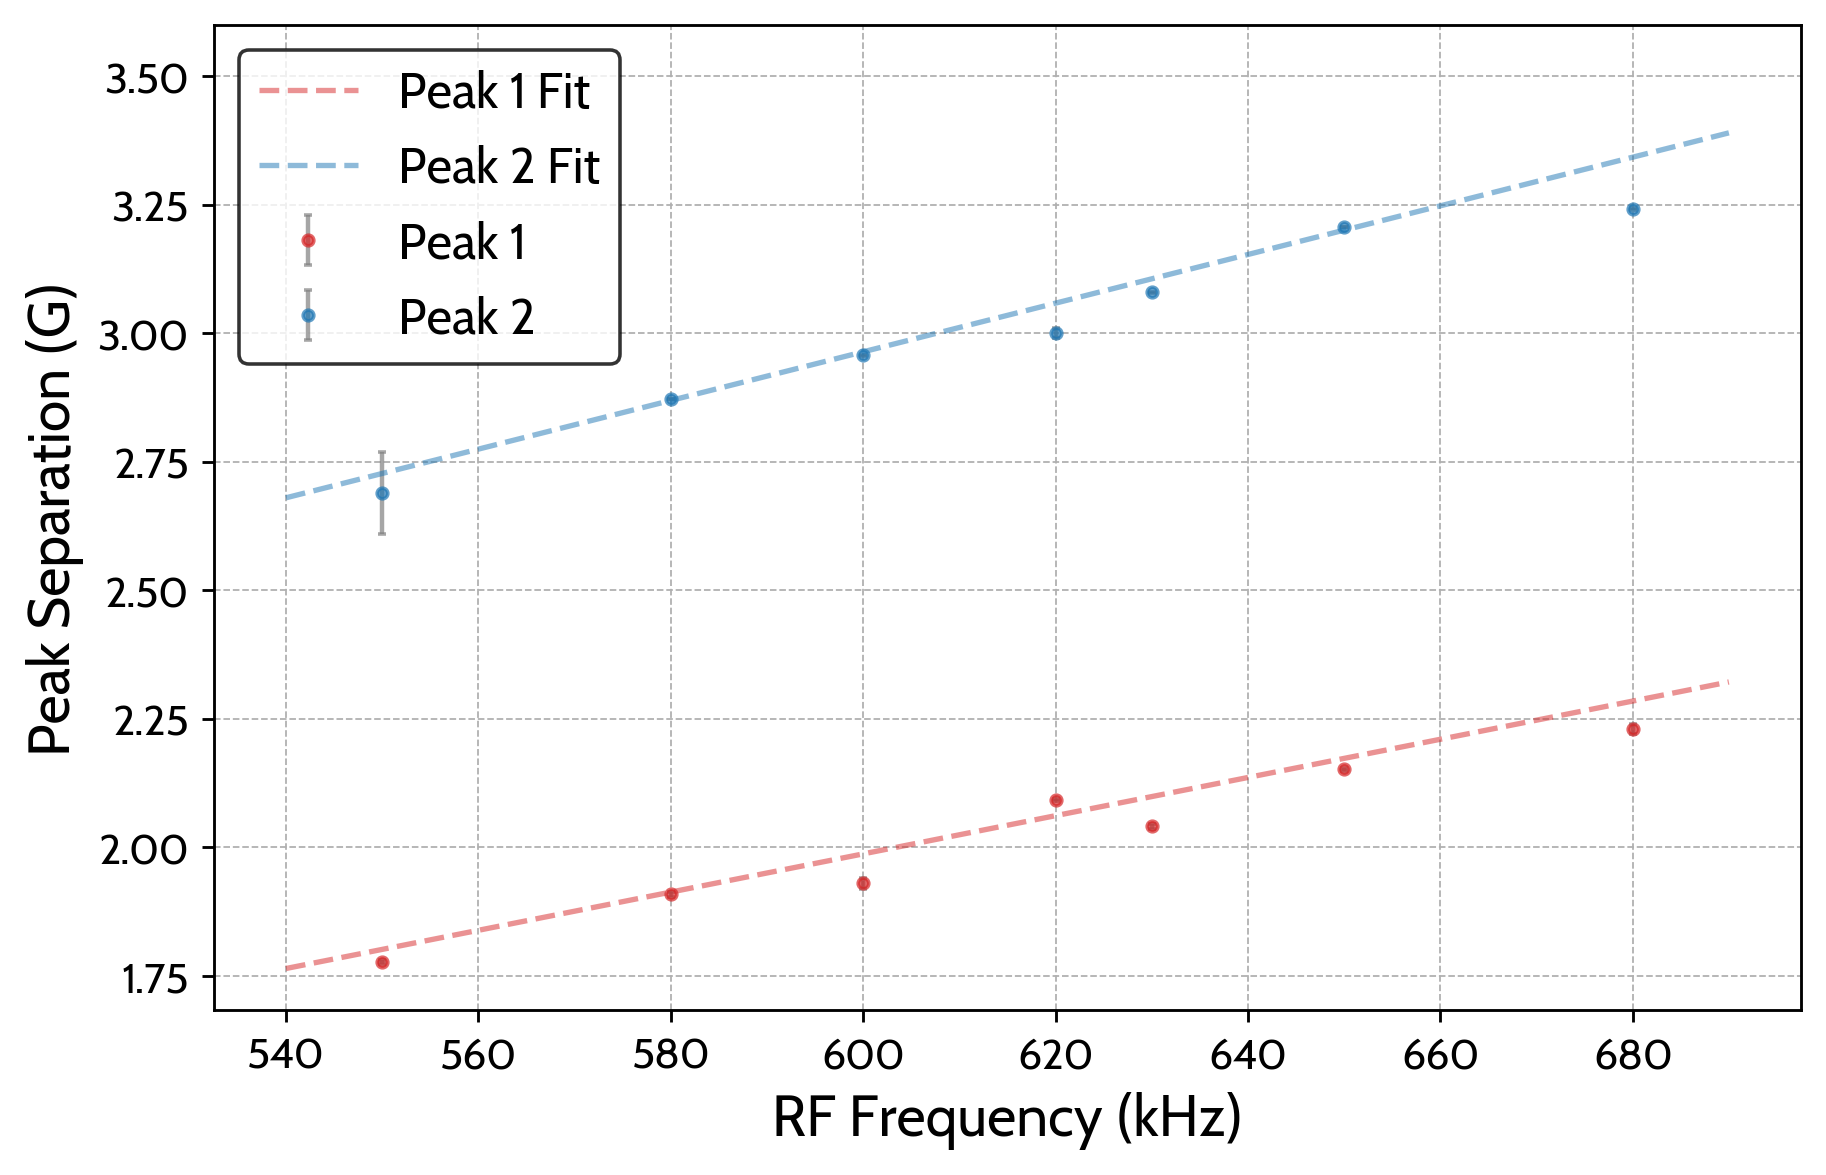

In [96]:
rf = np.array([650, 600, 550, 680, 630, 580, 620])
peak1 = np.array([2.152, 1.93, 1.777, 2.23, 2.041, 1.909, 2.092])
peak1_uncertainty = np.array([.003, .01, 0.004, 0.01, 0.005, 0.005, 0.002])
peak2 = np.array([3.2060, 2.957, 2.69, 3.241, 3.0794, 2.8722, 3.0])
peak2_uncertainty = np.array([0.0003, 0.001, 0.08, 0.002, 0.0009, 0.0009, 0.01])

def f(x, m, b):
    return m*x + b

popt1, pcov1 = curve_fit(f, rf, peak1, sigma=peak1_uncertainty)
popt2, pcov2 = curve_fit(f, rf, peak2, sigma=peak2_uncertainty)

xaxis = np.linspace(540, 690, 100)

fig, ax = plt.subplots(figsize=(8, 5), dpi = 256)
ax.errorbar(rf, peak1, yerr=peak1_uncertainty, color = "tab:red", fmt='o', ms=3, ecolor='gray', alpha=0.7, elinewidth=1.25, capsize=1, label  = "Peak 1")

ax.errorbar(rf, peak2, yerr=peak2_uncertainty, color = "tab:blue", fmt='o', ms=3, ecolor='gray', alpha=0.7, elinewidth=1.25, capsize=1, label  = "Peak 2")
ax.plot(xaxis, f(xaxis, *popt1), color = "tab:red", ls = "--", alpha=0.5, label = "Peak 1 Fit")
ax.plot(xaxis, f(xaxis, *popt2), color = "tab:blue", ls = "--", alpha=0.5, label = "Peak 2 Fit")


ax.set_xlabel('RF Frequency (kHz)')
ax.set_ylabel('Peak Separation (G)')
ax.legend(loc = "upper left")
ax.grid(True, which='both', linestyle='--', linewidth=0.5)

print(popt1, np.sqrt(np.diag(pcov1)))
print(popt2, np.sqrt(np.diag(pcov2)))
ax.set_ylim(None, 3.6)

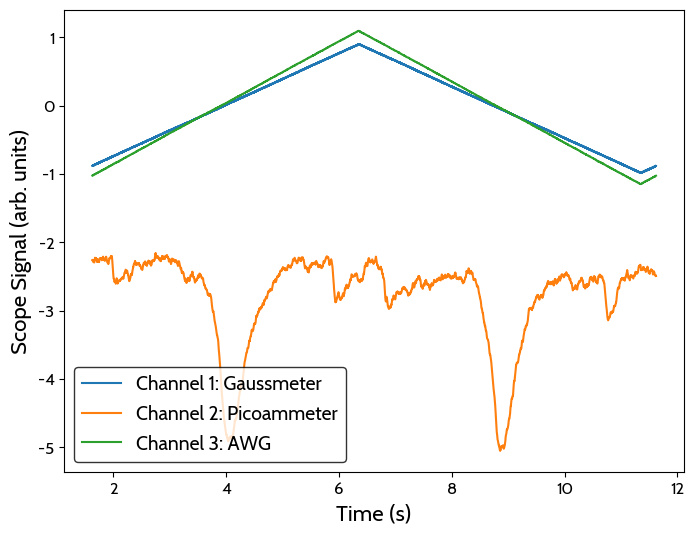

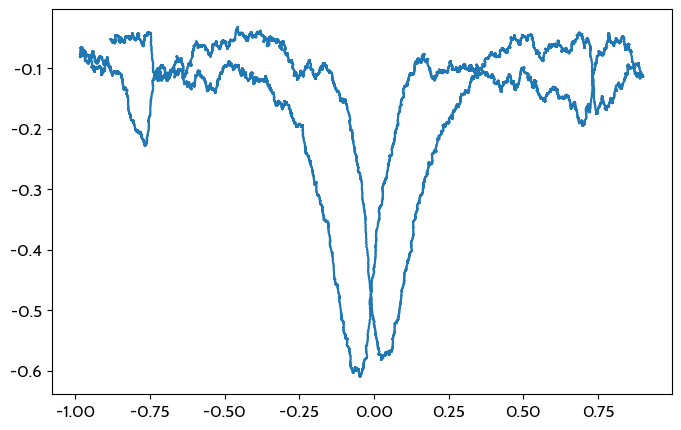

In [8]:
#testing scope ability
data = load_waveforms("data/22/test_23.npz")
t, V1, V2, V3 = data[1][0], data[1][1], data[2][1], data[3][1]

N = 400
t = np.convolve(t, np.ones(N)/N, mode='valid')
V1 = np.convolve(V1, np.ones(N)/N, mode='valid')
V2 = np.convolve(V2, np.ones(N)/N, mode='valid')
V3 = np.convolve(V3, np.ones(N)/N, mode='valid')


fig0, ax0 = plt.subplots(figsize=(8, 6))
ax0.plot(t, V1, label='Channel 1: Gaussmeter', color='tab:blue')
ax0.plot(t, V2*5-2, label='Channel 2: Picoammeter', color='tab:orange')
ax0.plot(t, V3, label='Channel 3: AWG', color='tab:green')
ax0.set_xlabel('Time (s)')
ax0.set_ylabel('Scope Signal (arb. units)')
ax0.legend()



fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(V1, V2, label='Channel 1: Gaussmeter', color='tab:blue')

In [9]:
# take data from scope
scope.save_waveforms("data/22/test")

NameError: name 'scope' is not defined